# 09 Shoreline maps: Figures 4 and 5

**Manuscript outputs:** Figure 4 (shorelines, baseline and transects), Figure 5 (Net Shoreline Movement map and transect-ordered profile)

**Inputs:** annual shorelines and DSAS transects/baseline (EPSG:32737), completed GLORYS attribution (stage 06, carries NSM and Zone), study zones, GADM county boundaries

The published Figures 4 and 5 were composed in a GIS. This notebook draws the same content from the same data so it can be regenerated; styling differs (no basemap, scale bar or inset of Kenya). Figure 1 (study area) is not reproduced.

Inputs are read from `Master_raw/`; outputs go to `Outputs/`.

In [10]:
from pathlib import Path

# ------------------------------------------------------------
# REPOSITORY ROOT: first folder above this notebook that contains Master_raw
# (e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024)
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No Master_raw folder found above {_here}. Open this notebook inside the repository.")
RAW = ROOT / "Master_raw"          # inputs
OUTPUTS = ROOT / "Outputs"         # everything this repository produces
FIGURES = OUTPUTS / "Figures"      # manuscript figures
TABLES = OUTPUTS / "Tables"        # manuscript tables
TEXT_STATS = TABLES / "Text_statistics"
for _d in (FIGURES, TABLES, TEXT_STATS):
    _d.mkdir(parents=True, exist_ok=True)
OVERWRITE = True                   # re-running replaces this notebook's earlier outputs


def first_existing(*candidates):
    """Return the first path that exists (otherwise the first one)."""
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return Path(candidates[0])


def save_table(df, name, index=False, folder=None):
    path = (folder or TABLES) / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Saved:", path.relative_to(ROOT))


def save_figure(fig, name, dpi=600):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight")
    print("Saved:", (FIGURES / f"{name}.jpeg").relative_to(ROOT))


def remove_existing(*files):
    for f in map(Path, files):
        for t in (list(f.parent.glob(f.stem + ".*")) if f.suffix == ".shp" else [f]):
            if t.exists():
                if not OVERWRITE:
                    raise FileExistsError(t)
                t.unlink()

# ------------------------------------------------------------
# INPUTS AND OUTPUT FOLDERS FOR THIS NOTEBOOK
# ------------------------------------------------------------
DSAS_INPUT_DIR = RAW / "DSAS_inputs"
SHORELINES_UTM_SHP = DSAS_INPUT_DIR / "ke_shorelines_2000_2024_UTM37S.shp"
TRANSECTS_GPKG = DSAS_INPUT_DIR / "ke_transects_30mtr.gpkg"
TRANSECT_LAYER = "ke_30mtr_transects"
BASELINE_LAYER = "ke_baseline"
TRANSECT_RATES_DIR = RAW / "Transect_rates"
BASE_MAPS = RAW / "Study_zones"
STUDY_ZONES_SHP = BASE_MAPS / "Study_zones_kwale_mom_Tana.shp"
GADM_KEN1_SHP = first_existing(BASE_MAPS / "gadm41_KEN_1.shp", RAW / "Base_maps" / "gadm41_KEN_1.shp")
GLORYS_DIR = OUTPUTS / "GLORYS_attribution"
COMPLETE_LAYER = "transects_complete"
COMPLETE_GPKG = first_existing(GLORYS_DIR / "ke_transects_GLORYS_complete_attribution_zoned.gpkg",
                               TRANSECT_RATES_DIR / "ke_transects_GLORYS_complete_attribution_zoned.gpkg")

print("Repository root:", ROOT)
for _label, _p in [("SHORELINES_UTM_SHP", SHORELINES_UTM_SHP), ("TRANSECTS_GPKG", TRANSECTS_GPKG), ("COMPLETE_GPKG", COMPLETE_GPKG), ("STUDY_ZONES_SHP", STUDY_ZONES_SHP), ("GADM_KEN1_SHP", GADM_KEN1_SHP)]:
    print(f"  {'ok     ' if _p.exists() else 'MISSING'} {_label}: {_p.relative_to(ROOT)}")


import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, ConnectionPatch
from shapely.geometry import box, Point

UTM = "EPSG:32737"

# Figure 4 zoom location (lon, lat). Default is the window shown in the published figure, south of Malindi.
ZOOM_LONLAT = (39.93, -3.51)
ZOOM_1_M = 3000      # width of the first zoom panel (m)
ZOOM_2_M = 250       # width of the second zoom panel (m)

# Figure 5 NSM classes (m): the natural-breaks classes used in the published figure
NSM_BREAKS = [-np.inf, -236, -51, 24, 114, 431, np.inf]
NSM_LABELS = ["\u2264 \u2212236", "\u2212236 to \u221251", "\u221251 to 24", "24 to 114", "114 to 431", "> 431"]
NSM_COLOURS = ["#e8202a", "#f5a623", "#d4f05c", "#6ee3d0", "#5aa0e6", "#5a1fd1"]

ZONE_ORDER = ["Tana-Manda", "Kilifi", "Kwale-Mombasa"]

Repository root: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
  ok      SHORELINES_UTM_SHP: Master_raw\DSAS_inputs\ke_shorelines_2000_2024_UTM37S.shp
  ok      TRANSECTS_GPKG: Master_raw\DSAS_inputs\ke_transects_30mtr.gpkg
  ok      COMPLETE_GPKG: Outputs\GLORYS_attribution\ke_transects_GLORYS_complete_attribution_zoned.gpkg
  ok      STUDY_ZONES_SHP: Master_raw\Study_zones\Study_zones_kwale_mom_Tana.shp
  ok      GADM_KEN1_SHP: Master_raw\Study_zones\gadm41_KEN_1.shp


## Load data

In [11]:
def year_field(cols):
    lower = {c.lower(): c for c in cols}
    for c in ["shre_yr", "year", "shore_year", "shoreyear", "date_"]:
        if c in lower:
            return lower[c]
    raise KeyError(f"No shoreline year field in {list(cols)}")

shorelines = gpd.read_file(SHORELINES_UTM_SHP).to_crs(UTM)
yf = year_field(shorelines.columns)
shorelines["Year"] = pd.to_numeric(shorelines[yf].astype(str).str[:4], errors="coerce").astype("Int64")
transects = gpd.read_file(TRANSECTS_GPKG, layer=TRANSECT_LAYER).to_crs(UTM)
baseline = gpd.read_file(TRANSECTS_GPKG, layer=BASELINE_LAYER).to_crs(UTM)
zones = gpd.read_file(STUDY_ZONES_SHP).to_crs(UTM)
counties = gpd.read_file(GADM_KEN1_SHP).to_crs(UTM)
complete = gpd.read_file(COMPLETE_GPKG, layer=COMPLETE_LAYER).to_crs(UTM)

years = sorted(shorelines["Year"].dropna().unique().tolist())
print(f"Shorelines: {len(shorelines):,} features, years {years[0]}\u2013{years[-1]}")
print(f"Transects: {len(transects):,}; completed attribution: {len(complete):,}")

cmap = plt.get_cmap("tab20b", 20)
cmap2 = plt.get_cmap("tab20c", 20)
YEAR_COLOURS = {y: (cmap(i) if i < 20 else cmap2(i - 20)) for i, y in enumerate(years)}
zone_name_col = next((c for c in zones.columns if c.lower() in ("zone", "name", "zone_name", "zones")), None)

Shorelines: 1,263 features, years 2000–2024
Transects: 12,468; completed attribution: 12,455


## Figure 4

C:\Users\jmbug\AppData\Local\Temp\ipykernel_20816\2937510033.py:51: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  b1.plot(ax=ax1, color="#7a1022", linewidth=1.6)


Saved: Outputs\Figures\Figure_4_Shorelines_baseline_and_transects.jpeg


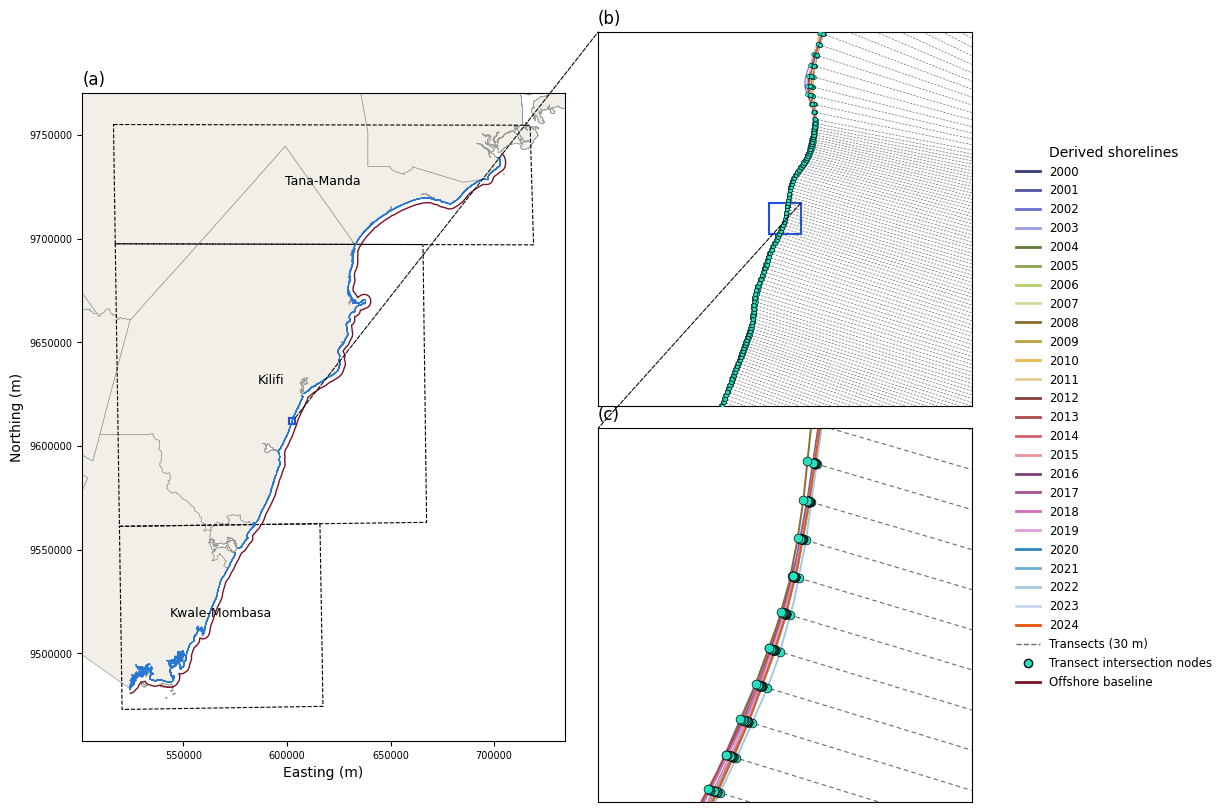

In [12]:
centre = gpd.GeoSeries([Point(*ZOOM_LONLAT)], crs="EPSG:4326").to_crs(UTM).iloc[0]

def window(c, width):
    h = width / 2
    return box(c.x - h, c.y - h, c.x + h, c.y + h)

# Centre the zoom on the shoreline crossings nearest to ZOOM_LONLAT
w0 = window(centre, ZOOM_1_M * 1.5)
t0 = transects.clip(w0)
s0 = shorelines.clip(w0)
nodes0 = gpd.overlay(t0[["geometry"]], s0[["Year", "geometry"]], how="intersection", keep_geom_type=False)
nodes0 = nodes0[nodes0.geom_type == "Point"]
if len(nodes0):
    near = nodes0.distance(centre).nsmallest(25).index
    centre = Point(nodes0.loc[near].geometry.x.median(), nodes0.loc[near].geometry.y.median())

w1, w2 = window(centre, ZOOM_1_M), window(centre, ZOOM_2_M)
t1, s1, b1 = transects.clip(w1), shorelines.clip(w1), baseline.clip(w1)
t2, s2 = transects.clip(w2), shorelines.clip(w2)
nodes1 = gpd.overlay(t1[["geometry"]], s1[["Year", "geometry"]], how="intersection", keep_geom_type=False)
nodes1 = nodes1[nodes1.geom_type == "Point"]
nodes2 = nodes1.clip(w2)

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 3, width_ratios=[1.25, 1, 0.42], height_ratios=[1, 1], wspace=0.08, hspace=0.06)
ax0 = fig.add_subplot(gs[:, 0])
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, 1])
axl = fig.add_subplot(gs[:, 2]); axl.axis("off")

# (a) overview
xmin, ymin, xmax, ymax = zones.total_bounds
pad = 15000
counties.plot(ax=ax0, color="#f1efe8", edgecolor="#9b9a96", linewidth=0.5)
zones.boundary.plot(ax=ax0, color="black", linewidth=0.8, linestyle="--")
if zone_name_col:
    for _, z in zones.iterrows():
        p = z.geometry.representative_point()
        ax0.text(p.x, p.y, str(z[zone_name_col]), ha="center", fontsize=9)
shorelines.plot(ax=ax0, color="#2a78d6", linewidth=0.6)
baseline.plot(ax=ax0, color="#7a1022", linewidth=1.0)
ax0.add_patch(Rectangle((w1.bounds[0], w1.bounds[1]), ZOOM_1_M, ZOOM_1_M, fill=False, edgecolor="#1f4fe0", linewidth=1.5))
ax0.set_xlim(xmin - pad, xmax + pad); ax0.set_ylim(ymin - pad, ymax + pad)
ax0.set_title("(a)", loc="left"); ax0.set_xlabel("Easting (m)"); ax0.set_ylabel("Northing (m)")
ax0.ticklabel_format(style="plain"); ax0.tick_params(labelsize=7)

# (b) first zoom
t1.plot(ax=ax1, color="#6b6a66", linewidth=0.5, linestyle=(0, (3, 2)))
for y, g in s1.groupby("Year"):
    g.plot(ax=ax1, color=YEAR_COLOURS[y], linewidth=0.8)
b1.plot(ax=ax1, color="#7a1022", linewidth=1.6)
nodes1.plot(ax=ax1, color="#22e0c0", edgecolor="#0b0b0b", markersize=8, linewidth=0.3, zorder=5)
ax1.add_patch(Rectangle((w2.bounds[0], w2.bounds[1]), ZOOM_2_M, ZOOM_2_M, fill=False, edgecolor="#1f4fe0", linewidth=1.5))
ax1.set_xlim(w1.bounds[0], w1.bounds[2]); ax1.set_ylim(w1.bounds[1], w1.bounds[3])
ax1.set_title("(b)", loc="left")

# (c) second zoom
t2.plot(ax=ax2, color="#6b6a66", linewidth=0.8, linestyle=(0, (4, 3)))
for y, g in s2.groupby("Year"):
    g.plot(ax=ax2, color=YEAR_COLOURS[y], linewidth=1.4)
nodes2.plot(ax=ax2, color="#22e0c0", edgecolor="#0b0b0b", markersize=40, linewidth=0.5, zorder=5)
ax2.set_xlim(w2.bounds[0], w2.bounds[2]); ax2.set_ylim(w2.bounds[1], w2.bounds[3])
ax2.set_title("(c)", loc="left")

for a in (ax1, ax2):
    a.set_xticks([]); a.set_yticks([]); a.set_xlabel(""); a.set_ylabel(""); a.set_aspect("equal")
ax0.set_aspect("equal")
for a, w in ((ax0, w1), (ax1, w2)):
    ax_to = ax1 if a is ax0 else ax2
    fig.add_artist(ConnectionPatch(xyA=(w.bounds[2], w.bounds[3]), coordsA=a.transData,
                                   xyB=(0, 1), coordsB=ax_to.transAxes, linestyle="--", color="#0b0b0b", linewidth=0.8))

handles = [Line2D([0], [0], color=YEAR_COLOURS[y], lw=2, label=str(y)) for y in years]
handles += [Line2D([0], [0], color="#6b6a66", lw=1, ls="--", label="Transects (30 m)"),
            Line2D([0], [0], marker="o", ls="none", markerfacecolor="#22e0c0", markeredgecolor="#0b0b0b", label="Transect intersection nodes"),
            Line2D([0], [0], color="#7a1022", lw=2, label="Offshore baseline")]
axl.legend(handles=handles, title="Derived shorelines", loc="center left", frameon=False, fontsize=8.5, title_fontsize=10)
save_figure(fig, "Figure_4_Shorelines_baseline_and_transects", dpi=400)
plt.show()

## Figure 5

Saved: Outputs\Figures\Figure_5_Net_shoreline_movement_map_and_profile.jpeg


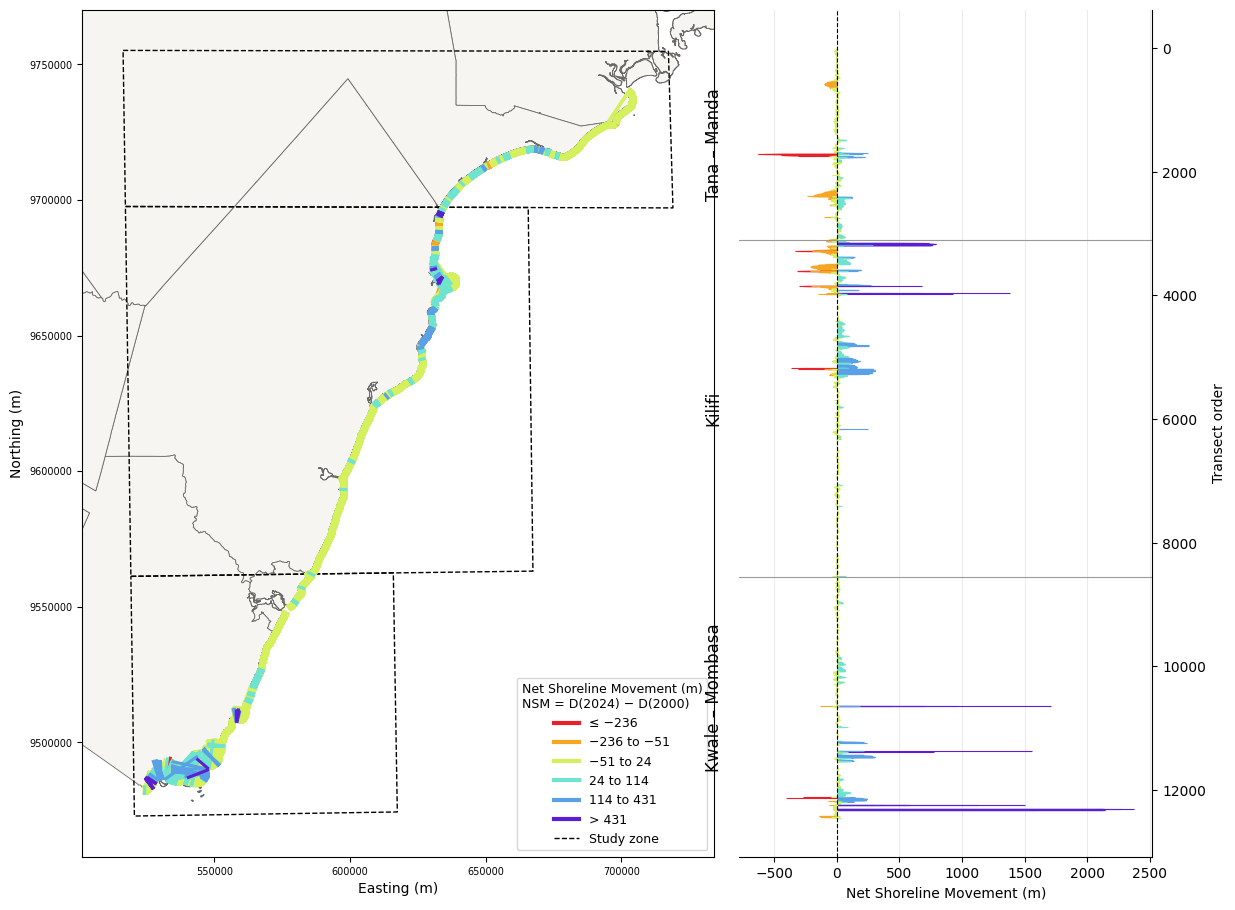

In [13]:
nsm = complete.copy()
nsm["NSM"] = pd.to_numeric(nsm["NSM"], errors="coerce")
nsm = nsm.dropna(subset=["NSM"])
nsm["NSM_class"] = pd.cut(nsm["NSM"], NSM_BREAKS, labels=False, include_lowest=True)

# Transect order runs north (Tana-Manda) to south (Kwale-Mombasa), as in the published profile.
tid = pd.to_numeric(nsm["Transect_ID"], errors="coerce")
if tid.notna().all():
    nsm["Order"] = tid
else:
    nsm["Order"] = (-nsm.geometry.centroid.y).rank(method="first")
if nsm.loc[nsm.Zone == "Tana-Manda", "Order"].mean() > nsm.loc[nsm.Zone == "Kwale-Mombasa", "Order"].mean():
    nsm["Order"] = nsm["Order"].max() + nsm["Order"].min() - nsm["Order"]
nsm = nsm.sort_values("Order")

fig = plt.figure(figsize=(14, 11))
gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], wspace=0.02)
ax = fig.add_subplot(gs[0, 0])
axp = fig.add_subplot(gs[0, 1])

xmin, ymin, xmax, ymax = zones.total_bounds
pad = 15000
counties.plot(ax=ax, color="#f6f5f1", edgecolor="#6b6a66", linewidth=0.6)
zones.boundary.plot(ax=ax, color="black", linewidth=1.0, linestyle="--")
for k, colour in enumerate(NSM_COLOURS):
    sub = nsm[nsm.NSM_class == k]
    if len(sub):
        sub.plot(ax=ax, color=colour, linewidth=2.2)
ax.set_xlim(xmin - pad, xmax + pad); ax.set_ylim(ymin - pad, ymax + pad)
ax.set_aspect("equal"); ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=7)
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
handles = [Line2D([0], [0], color=c, lw=3, label=l) for c, l in zip(NSM_COLOURS, NSM_LABELS)]
handles.append(Line2D([0], [0], color="black", lw=1, ls="--", label="Study zone"))
ax.legend(handles=handles, title="Net Shoreline Movement (m)\nNSM = D(2024) \u2212 D(2000)",
          loc="lower right", frameon=True, fontsize=9, title_fontsize=9)

colours = np.array(NSM_COLOURS)[nsm["NSM_class"].astype(int).to_numpy()]
axp.hlines(nsm["Order"], 0, nsm["NSM"], colors=colours, linewidth=0.8)
axp.axvline(0, color="black", linestyle="--", linewidth=0.8)
axp.invert_yaxis()
axp.yaxis.tick_right(); axp.yaxis.set_label_position("right")
axp.set_ylabel("Transect order"); axp.set_xlabel("Net Shoreline Movement (m)")
for z in ZONE_ORDER:
    o = nsm.loc[nsm.Zone == z, "Order"]
    if len(o):
        axp.text(-0.04, (o.min() + o.max()) / 2, z.replace("-", " \u2013 "), transform=axp.get_yaxis_transform(),
                 rotation=90, ha="right", va="center", fontsize=12)
for z in ZONE_ORDER[1:]:
    o = nsm.loc[nsm.Zone == z, "Order"]
    if len(o):
        axp.axhline(o.min(), color="#9b9a96", linewidth=0.8)
axp.grid(axis="x", alpha=0.25)
for s in ("top", "left"):
    axp.spines[s].set_visible(False)
save_figure(fig, "Figure_5_Net_shoreline_movement_map_and_profile", dpi=400)
plt.show()